# V2 kayitli sonuclar — salt okuma; completed fiziksel kabul degildir.


Grup: completed | completed fiziksel kabul degildir


,experiment_id,scenario_id,state,controls,calculation,k,MC_standard_error,duration_s,fields_npz,summary_json,physical_acceptance,statistical_convergence
0,V2-HALTON_01-0001,5228e2093c1a5318dfb3d65897286a2a104f4155cd3563...,completed,{'u235_enrichment_wt_percent': 2.2699262907697...,"{'particles_per_generation': 80000, 'batches':...",1.139862,0.000175,1096.235238,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
1,V2-HALTON_01-0002,5c399a73c8950621c8f5d182e776583be798def6407ef7...,completed,{'u235_enrichment_wt_percent': 1.8949262907697...,"{'particles_per_generation': 80000, 'batches':...",1.060954,0.000182,1109.518163,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
2,V2-HALTON_01-0003,f59a6b46cdf74531a937587a96673e28e4e60991587a5e...,completed,{'u235_enrichment_wt_percent': 2.6449262907697...,"{'particles_per_generation': 80000, 'batches':...",1.151542,0.000178,941.877693,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
3,V2-HALTON_01-0004,bcf6ffa092bc07f27ebfcc48131a1b670a42f73a34ddf8...,completed,{'u235_enrichment_wt_percent': 1.7074262907697...,"{'particles_per_generation': 80000, 'batches':...",1.166914,0.000185,1070.525203,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
4,V2-HALTON_01-0005,ee85c54df135852660a512683019bd87644f78b52558a0...,completed,{'u235_enrichment_wt_percent': 2.4574262907697...,"{'particles_per_generation': 80000, 'batches':...",1.242032,0.000187,987.665419,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
5,V2-HALTON_01-0006,3cbb1b2fab7c418a8f03df598d87fa43c7d796ab80e2ef...,completed,{'u235_enrichment_wt_percent': 2.0824262907697...,"{'particles_per_generation': 80000, 'batches':...",1.154752,0.000186,1000.056282,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
6,V2-HALTON_01-0007,02aa46a7183f2ab10db95dadb20be2b8077461aa7c6fae...,completed,{'u235_enrichment_wt_percent': 2.8324262907697...,"{'particles_per_generation': 80000, 'batches':...",1.185118,0.000184,945.558579,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
7,V2-HALTON_01-0008,4bc6e0cf6779944ca386083a54a49083c80d9e53d58578...,completed,{'u235_enrichment_wt_percent': 2.9730512907697...,"{'particles_per_generation': 80000, 'batches':...",1.103364,0.000208,924.247456,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
8,V2-HALTON_01-0009,57940e656e41fc3ef4830086b205df173febd0a45a3f45...,completed,{'u235_enrichment_wt_percent': 2.2230512907697...,"{'particles_per_generation': 80000, 'batches':...",0.865086,0.000162,936.710334,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
9,V2-HALTON_01-0010,a7584518f64471b57acfa3313b6753776647af9b24e5ee...,completed,{'u235_enrichment_wt_percent': 1.8480512907697...,"{'particles_per_generation': 80000, 'batches':...",0.715590,0.000162,988.514371,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required


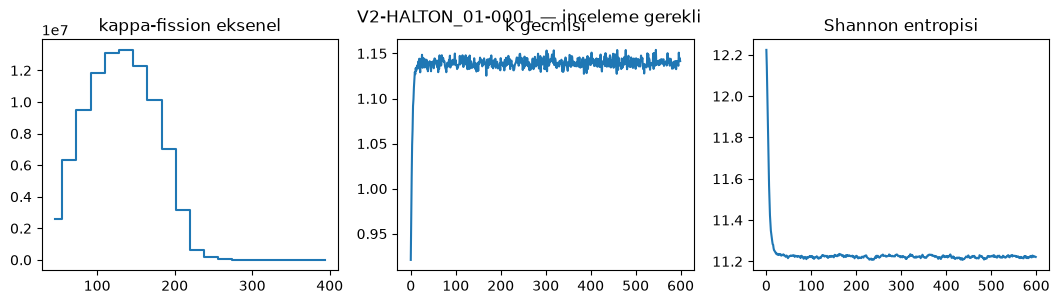

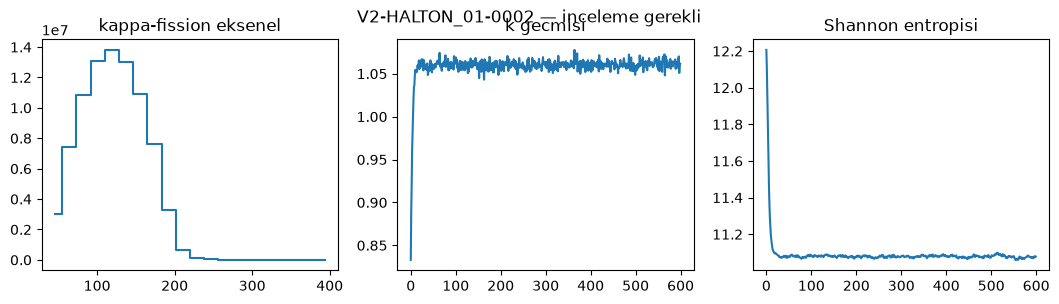

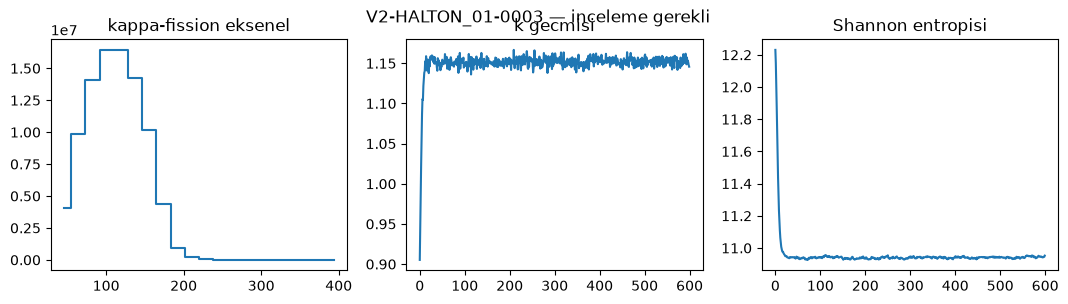

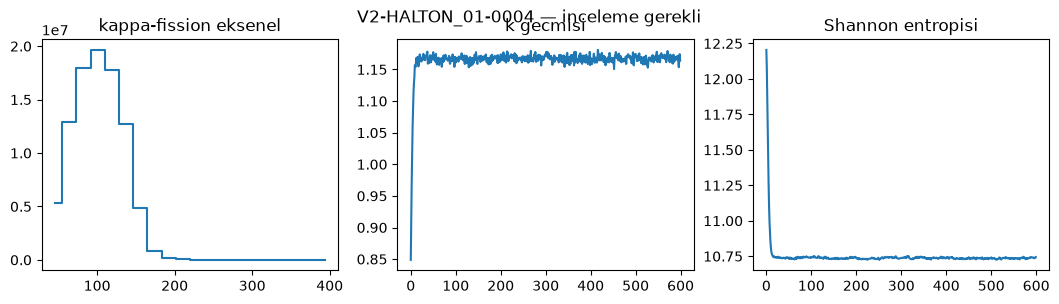

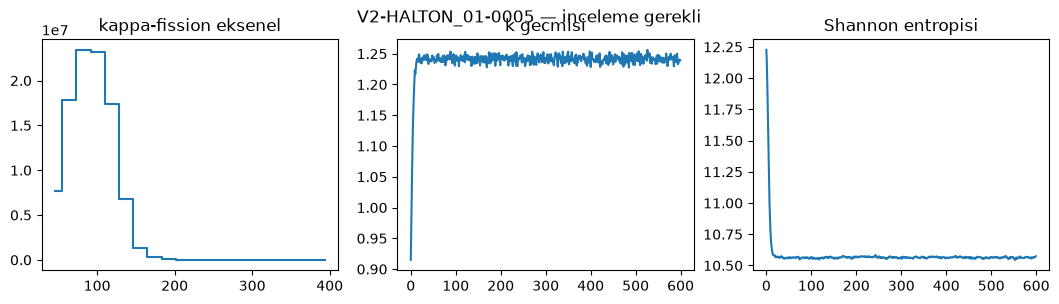

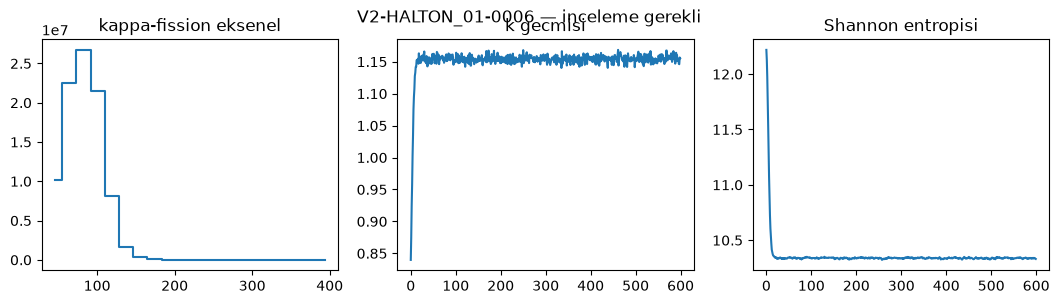

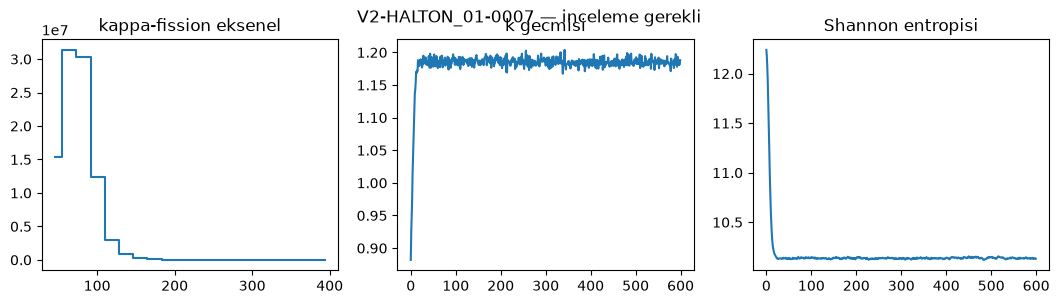

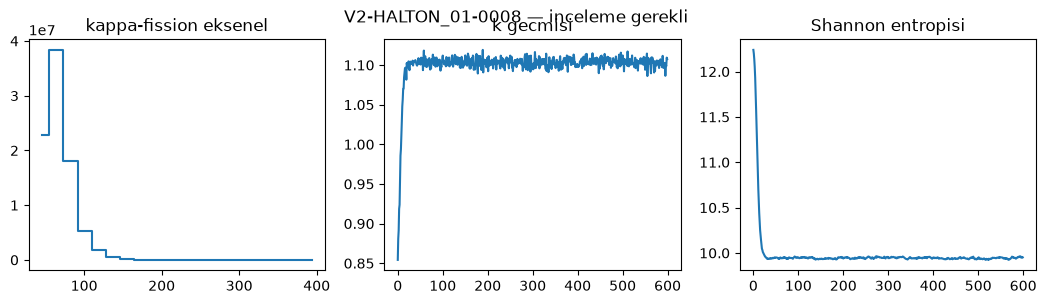

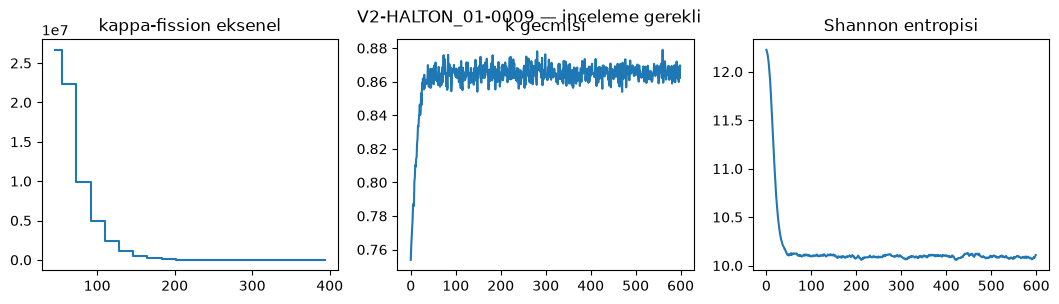

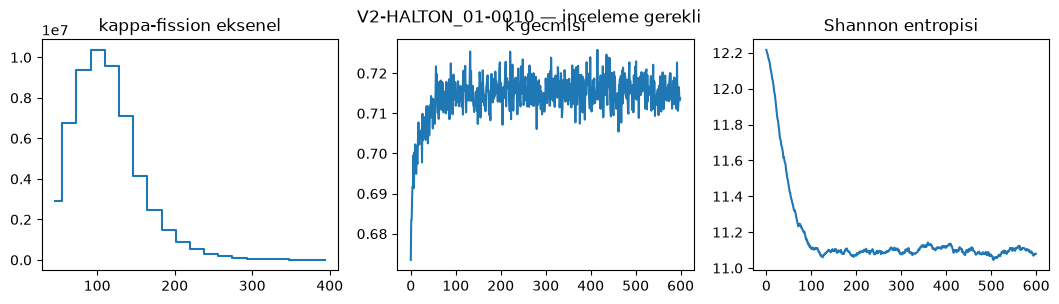

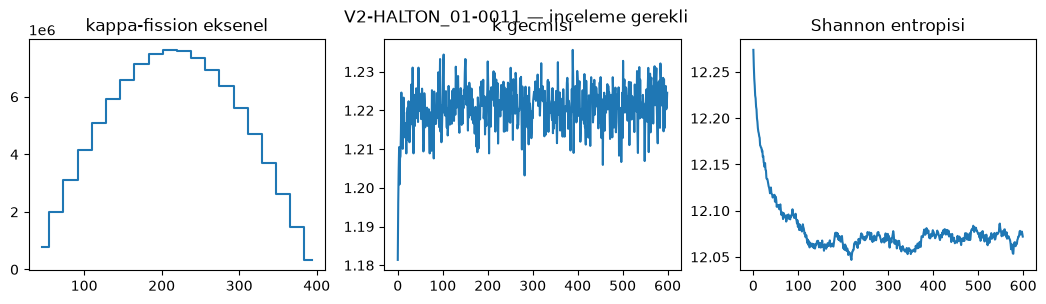

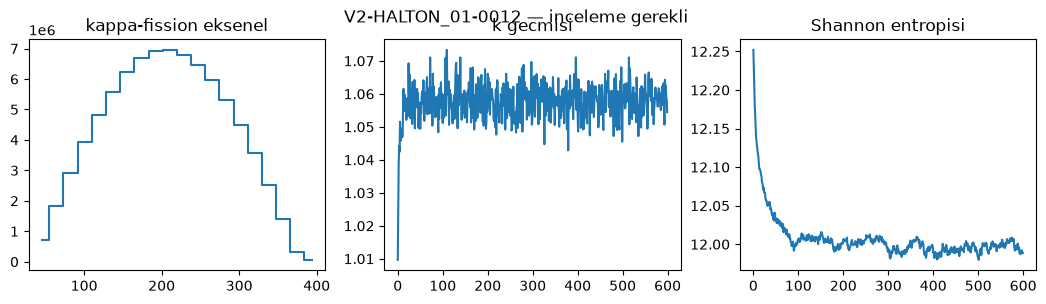

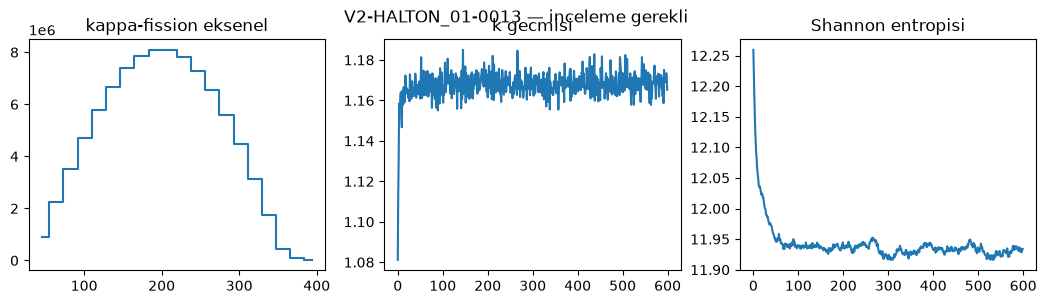

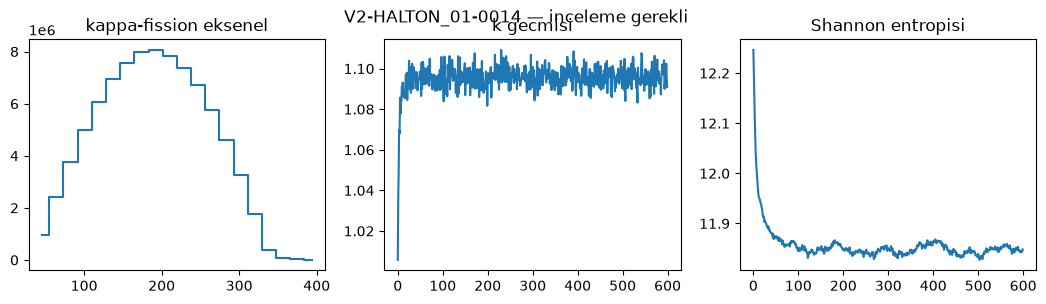

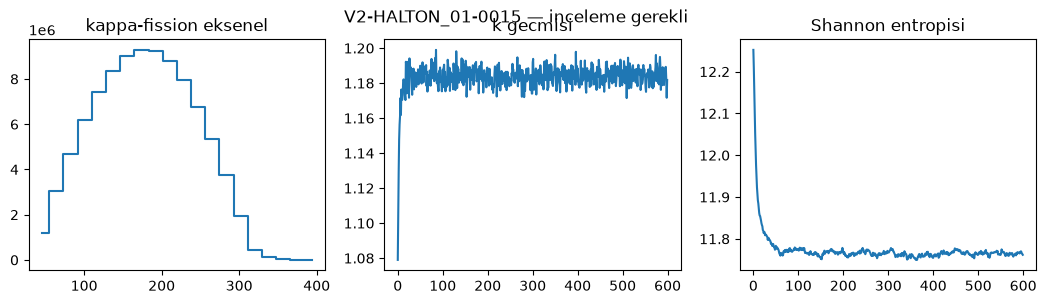

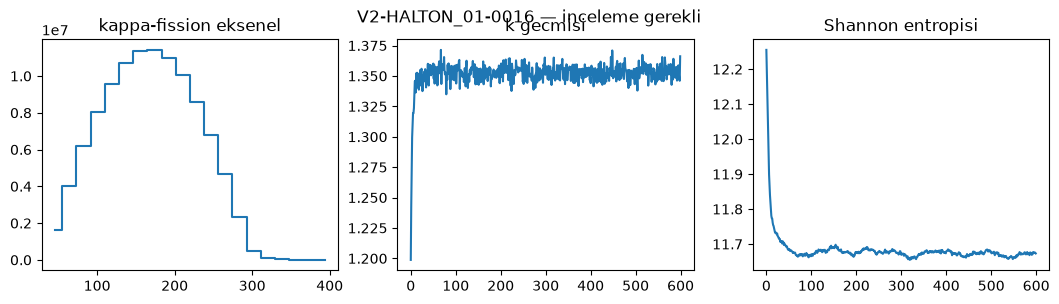

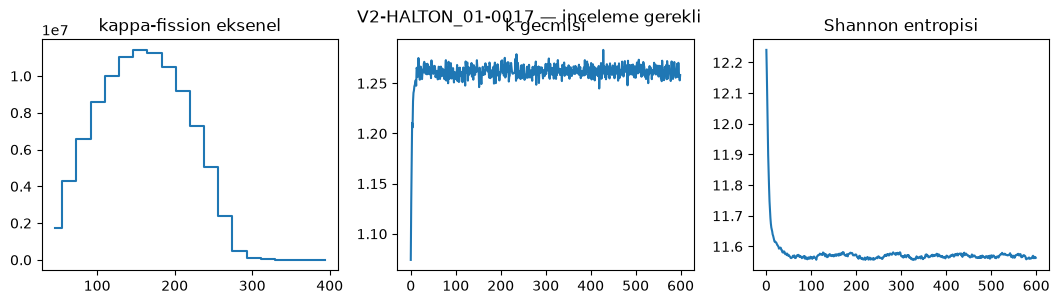

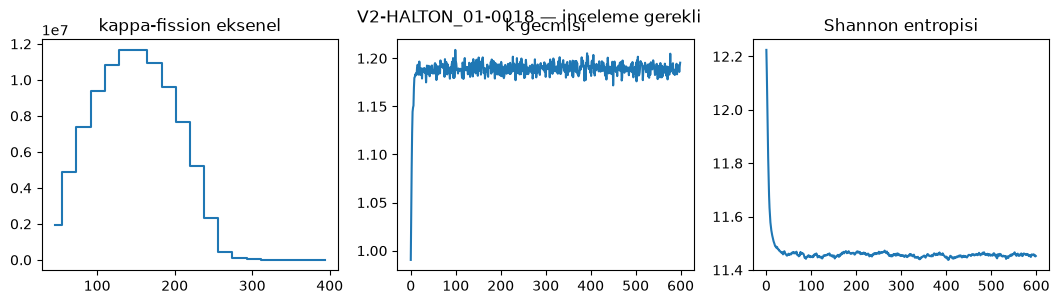

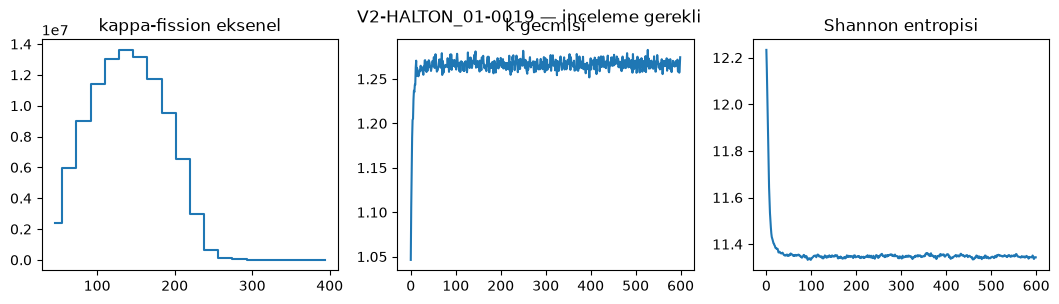

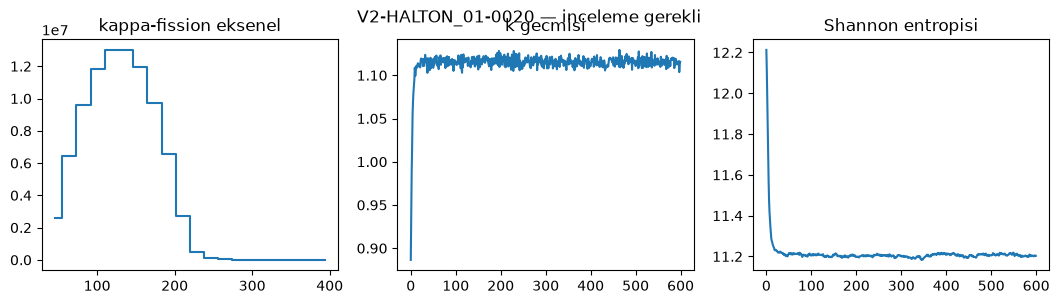

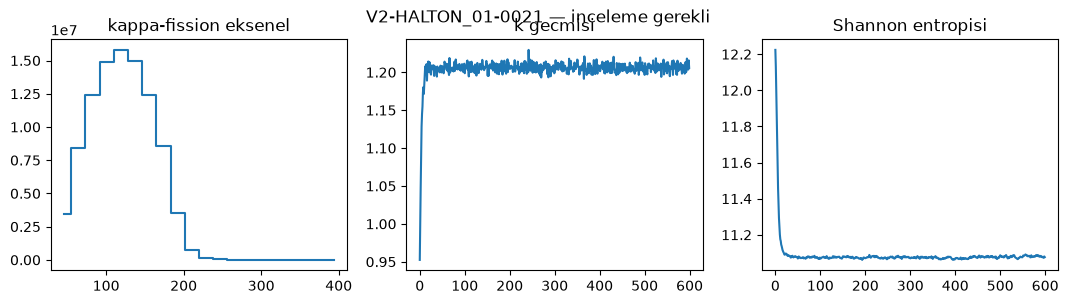

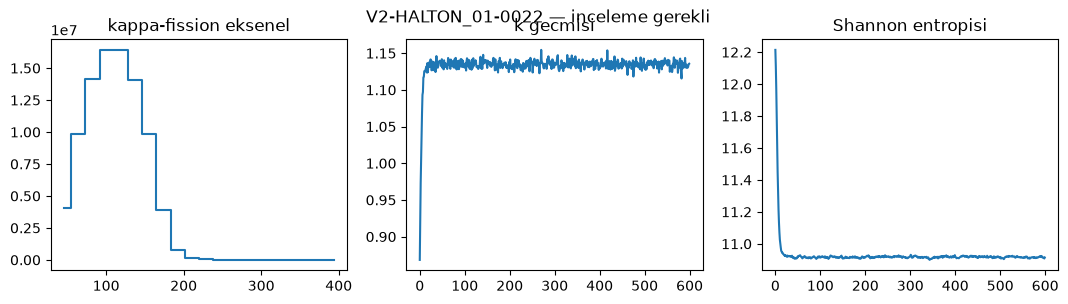

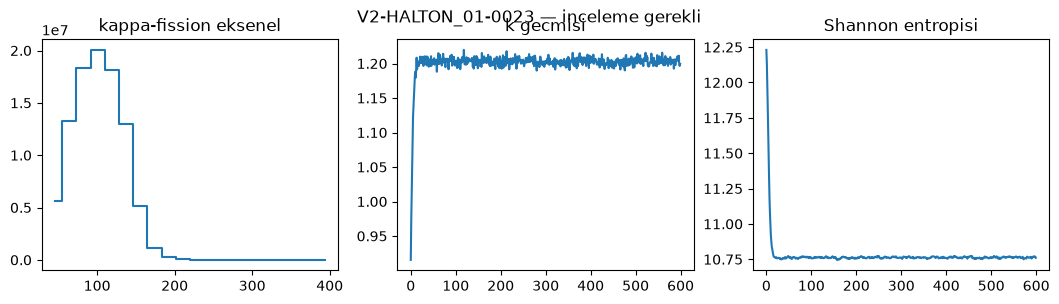

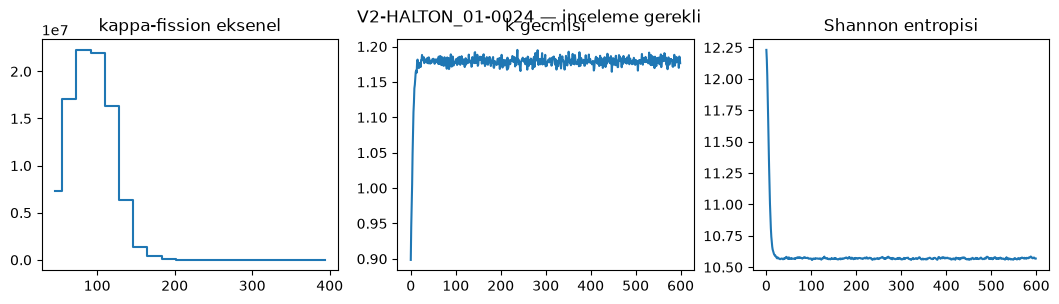

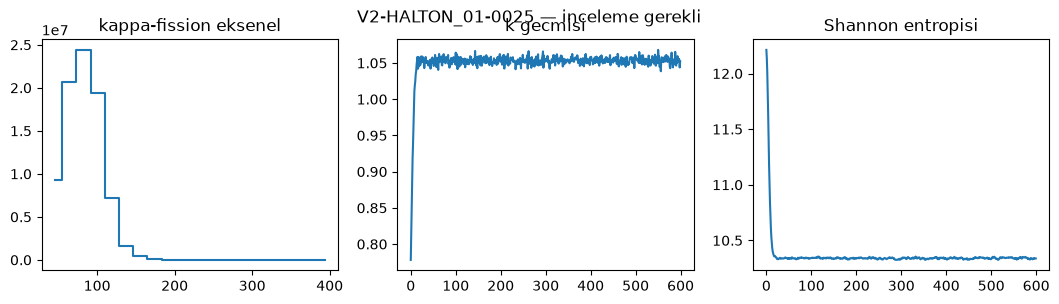

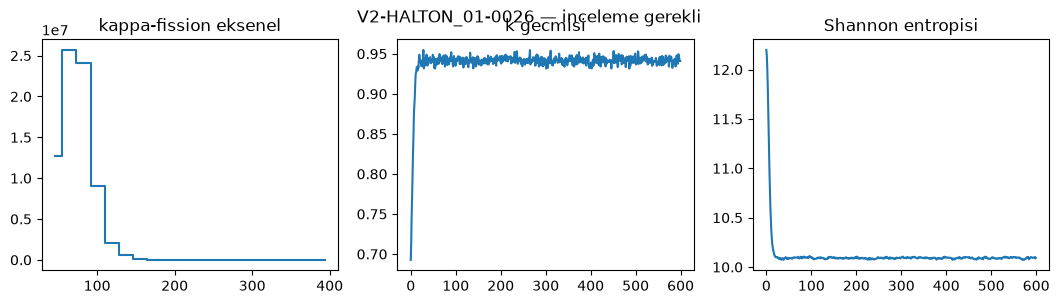

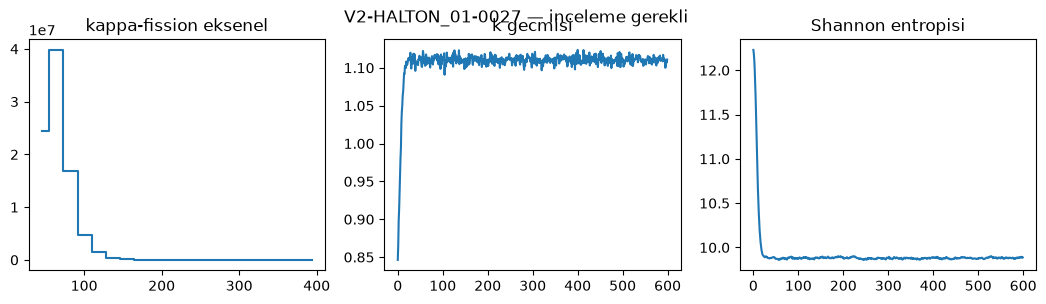

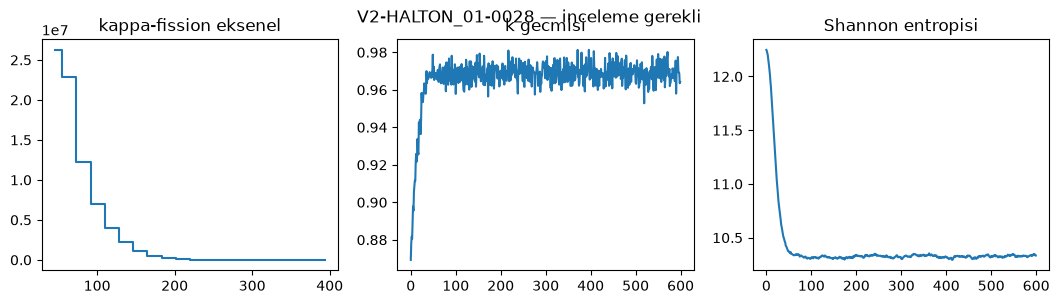

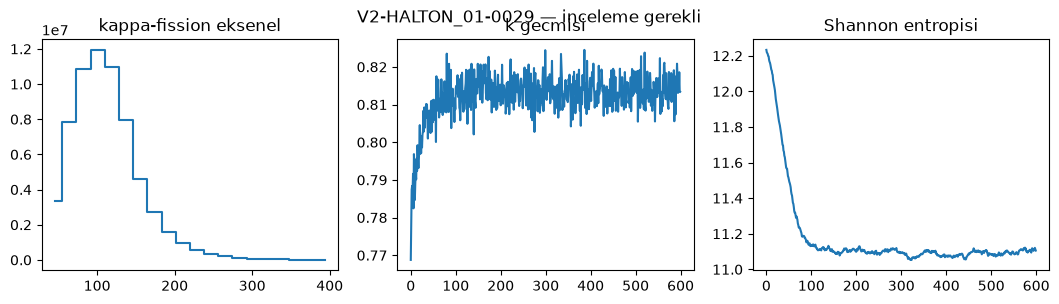

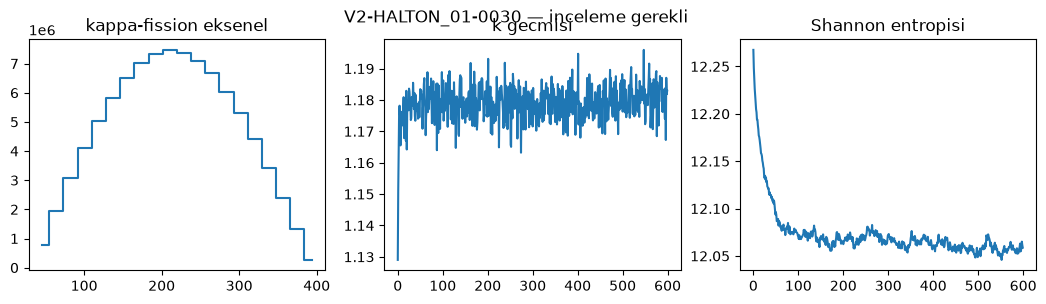

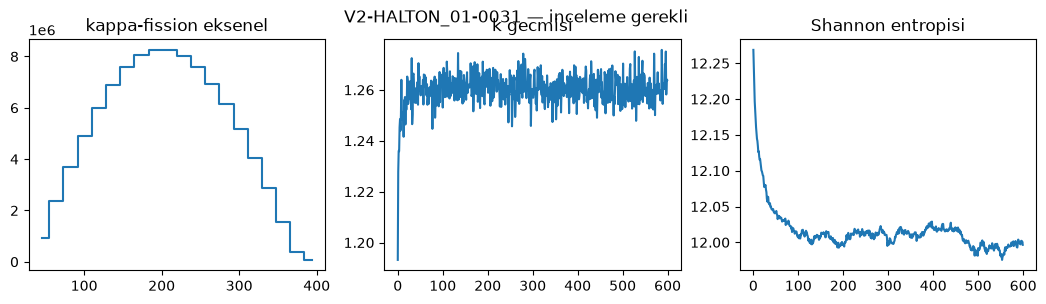

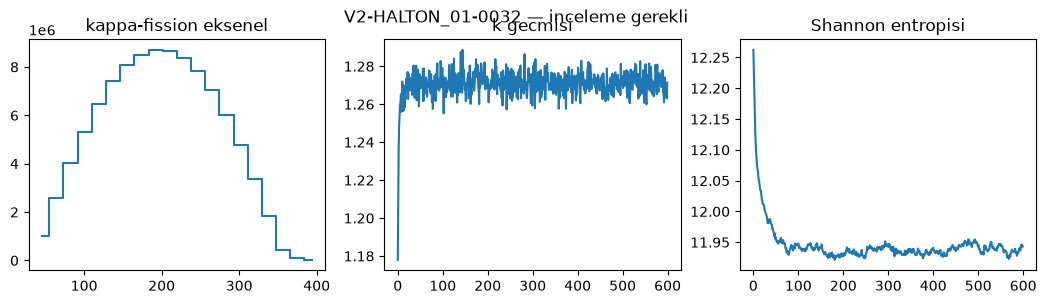

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json, sys
PACKAGE = Path.cwd().resolve()
PROJECT = next(p for p in (PACKAGE, *PACKAGE.parents) if (p / "src/reactor_pipeline/v2_students.py").is_file())
sys.path.insert(0, str(PROJECT / "src"))
from reactor_pipeline import v2_student_runner, v2_students
assert PACKAGE.name == "v2_halton_01_beavrs_v2_pilot_scope_v1"
info = v2_students.verify_package(PACKAGE, require_approval=False)
saved = v2_student_runner.saved_results(PACKAGE)
print("Grup:", saved["group"]["state"], "| completed fiziksel kabul degildir")
rows = []
for case in saved["cases"]:
    summary = case["summary"] or {}
    k = summary.get("k_effective", {})
    manifest_case = next(x for x in v2_students._read(PACKAGE / "manifest.json")["experiments"]
                         if x["experiment_id"] == case["experiment_id"])
    rows.append({"experiment_id": case["experiment_id"],
                 "scenario_id": case["scenario_id"], "state": case["state"],
                 "controls": manifest_case["controls"], "calculation": manifest_case["calculation"],
                 "k": k.get("mean"), "MC_standard_error": k.get("mc_standard_error"),
                 "duration_s": summary.get("duration", {}).get("value"),
                 "fields_npz": str(Path(case["attempt"]) / "fields.npz") if case["attempt"] else None,
                 "summary_json": str(Path(case["attempt"]) / "summary.json") if case["attempt"] else None,
                 "physical_acceptance": case["physical_acceptance"],
                 "statistical_convergence": case["statistical_convergence"]})
display(pd.DataFrame(rows))
for case in saved["cases"]:
    if case["state"] != "completed":
        continue
    with np.load(Path(case["attempt"]) / "fields.npz", allow_pickle=False) as fields:
        z = fields["z_edges_cm"]
        axial = fields["kappa_fission_mean"].sum(axis=(1, 2))
        k_history = fields["k_generation"].copy()
        entropy = fields["shannon_entropy"].copy()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].step((z[:-1]+z[1:])/2, axial, where="mid")
    axes[0].set_title("kappa-fission eksenel")
    axes[1].plot(k_history); axes[1].set_title("k gecmisi")
    axes[2].plot(entropy); axes[2].set_title("Shannon entropisi")
    fig.suptitle(case["experiment_id"] + " — inceleme gerekli")
    display(fig)
    plt.close(fig)


## Teslim — hesap başlatmaz
Tamamlanan koşular için WSL terminalinde: `python scripts/v2_transfer.py export student_packages/v2_halton128_v1/halton_01/v2_halton_01_beavrs_v2_pilot_scope_v1 deliveries/v2_halton_01_beavrs_v2_pilot_scope_v1.zip`. Durum `completed` olmadan teslim tam sayılmaz; varsayılan ZIP statepoint içermez.
